<a href="https://colab.research.google.com/github/ShamiPlacide/SortFlow/blob/main/notebook/Untitled2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Problem statement and imports


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 2. Data loading and class distribution (bar chart)

In [2]:
import os
from google.colab import userdata
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')

In [3]:
!pip install -q --upgrade kaggle
!kaggle datasets download -d mostafaabla/garbage-classification -p /content/raw --unzip
!find /content/raw -maxdepth 3 -type d

Dataset URL: https://www.kaggle.com/datasets/mostafaabla/garbage-classification
License(s): ODbL-1.0
100% 239M/239M [00:01<00:00, 220MB/s]

/content/raw
/content/raw/garbage_classification
/content/raw/garbage_classification/white-glass
/content/raw/garbage_classification/trash
/content/raw/garbage_classification/cardboard
/content/raw/garbage_classification/biological
/content/raw/garbage_classification/shoes
/content/raw/garbage_classification/paper
/content/raw/garbage_classification/plastic
/content/raw/garbage_classification/clothes
/content/raw/garbage_classification/green-glass
/content/raw/garbage_classification/brown-glass
/content/raw/garbage_classification/metal
/content/raw/garbage_classification/battery


In [4]:
import random, shutil
from pathlib import Path

random.seed(42)
SRC = Path('/content/raw/garbage_classification')   # adjust to what find printed
DST = Path('/content/drive/MyDrive/waste_data')

MAPPING = {
    'cardboard': 'cardboard', 'metal': 'metal', 'paper': 'paper',
    'plastic': 'plastic', 'biological': 'organic',
    'brown-glass': 'glass', 'green-glass': 'glass', 'white-glass': 'glass',
}

# collect files per target class
by_class = {}
for src_cls, tgt in MAPPING.items():
    for f in (SRC / src_cls).glob('*'):
        if f.suffix.lower() in {'.jpg', '.jpeg', '.png'}:
            by_class.setdefault(tgt, []).append(f)

for cls, files_ in by_class.items():
    random.shuffle(files_)
    n = len(files_)
    splits = {'train': files_[:int(.7*n)],
              'val':   files_[int(.7*n):int(.85*n)],
              'test':  files_[int(.85*n):]}
    for split, items in splits.items():
        out = DST / split / cls
        out.mkdir(parents=True, exist_ok=True)
        for i, f in enumerate(items):
            shutil.copy(f, out / f"{f.parent.name}_{f.name}")
    print(cls, n)

cardboard 891
metal 769
paper 1050
plastic 865
organic 985
glass 2011


# 3. EDA with at least 3 interpreted features, for example:
class imbalance and what it means for metrics
image brightness or color per class (e.g., glass vs. cardboard)
image dimensions and aspect ratios, and why you resize
sample grid per class, showing visually confusing pairs like paper vs. cardboard

In [5]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import random

DST = Path('/content/drive/MyDrive/waste_data')
CLASSES = sorted(p.name for p in (DST/'train').iterdir())

rows = []
for split in ['train', 'val', 'test']:
    for cls in CLASSES:
        rows.append((split, cls, len(list((DST/split/cls).glob('*')))))
df_counts = pd.DataFrame(rows, columns=['split', 'class', 'count'])
print(df_counts.pivot(index='class', columns='split', values='count'))

split      test  train  val
class                      
cardboard   247    814  250
glass       547   1814  554
metal       221    706  216
organic     276    889  271
paper       296    964  295
plastic     235    782  240


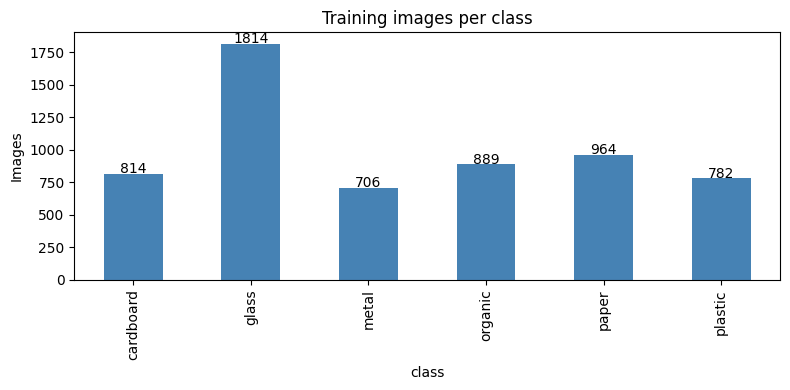

Imbalance ratio (max/min): 2.57


In [6]:
train_counts = df_counts[df_counts.split == 'train'].set_index('class')['count']
ax = train_counts.plot(kind='bar', figsize=(8, 4), color='steelblue')
ax.set_title('Training images per class'); ax.set_ylabel('Images')
for i, v in enumerate(train_counts): ax.text(i, v + 5, str(v), ha='center')
plt.tight_layout(); plt.show()
print('Imbalance ratio (max/min):', round(train_counts.max() / train_counts.min(), 2))

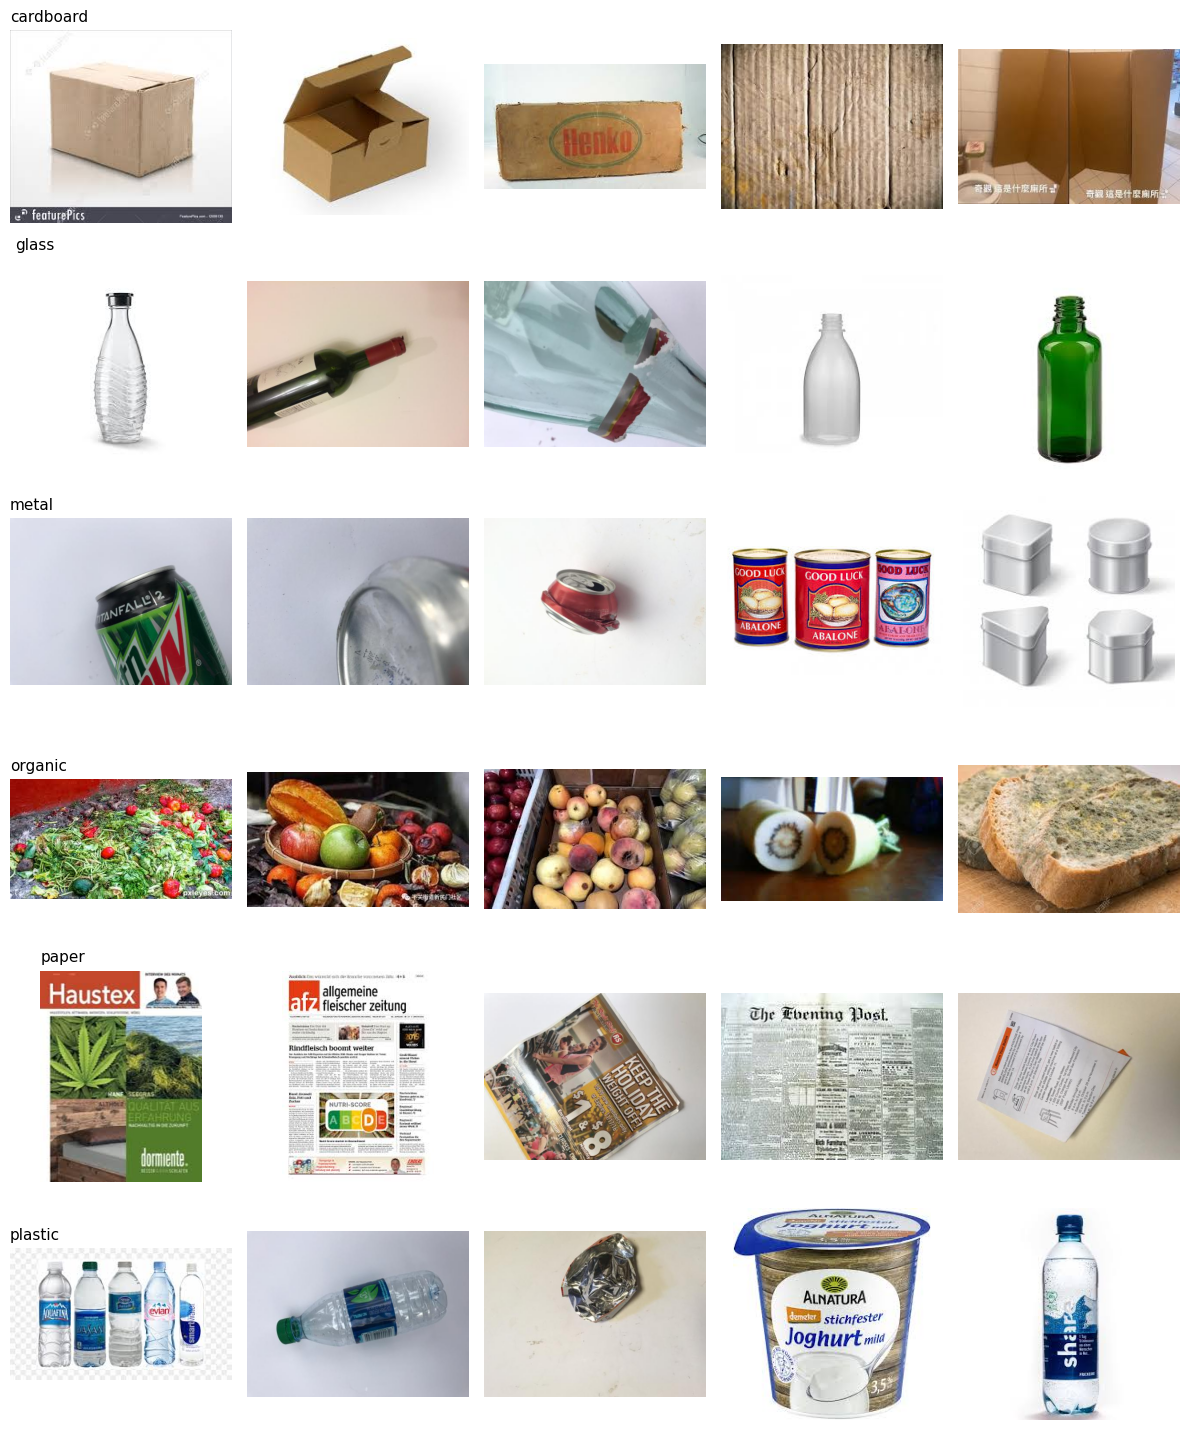

In [7]:
fig, axes = plt.subplots(len(CLASSES), 5, figsize=(12, 2.4 * len(CLASSES)))
for r, cls in enumerate(CLASSES):
    files = random.sample(list((DST/'train'/cls).glob('*')), 5)
    for c, f in enumerate(files):
        axes[r, c].imshow(Image.open(f).convert('RGB')); axes[r, c].axis('off')
        if c == 0: axes[r, c].set_title(cls, loc='left', fontsize=11)
plt.tight_layout(); plt.show()

                w               h        aspect      
             mean     std    mean    std   mean   std
class                                                
cardboard  364.66  135.47  287.02  89.67   1.26  0.21
glass      284.18  128.47  271.14  71.10   1.04  0.30
metal      382.20  138.29  301.13  89.25   1.27  0.27
organic    261.21   31.99  196.17  27.85   1.37  0.32
paper      372.70  139.63  296.28  90.18   1.28  0.39
plastic    383.20  142.90  310.33  84.49   1.23  0.29


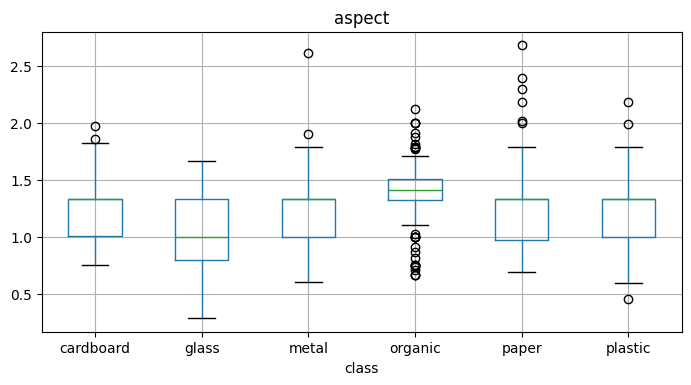

In [8]:
recs = []
for cls in CLASSES:
    for f in random.sample(list((DST/'train'/cls).glob('*')), 100):
        w, h = Image.open(f).size
        recs.append((cls, w, h, w / h))
df_size = pd.DataFrame(recs, columns=['class', 'w', 'h', 'aspect'])
print(df_size.groupby('class')[['w', 'h', 'aspect']].agg(['mean', 'std']).round(2))
df_size.boxplot(column='aspect', by='class', figsize=(8, 4)); plt.suptitle(''); plt.show()

           brightness           R           G           B
class                                                    
cardboard  167.000000  187.800003  166.399994  146.899994
glass      181.600006  186.800003  185.300003  172.800003
metal      178.800003  181.699997  178.899994  175.899994
organic    142.699997  171.199997  144.399994  112.500000
paper      168.199997  176.500000  167.800003  160.300003
plastic    180.199997  179.300003  180.600006  180.899994


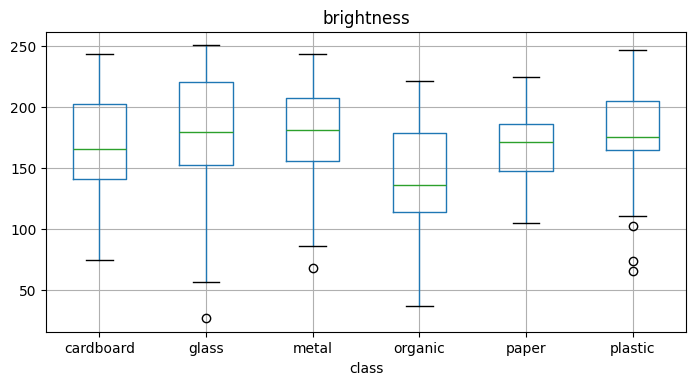

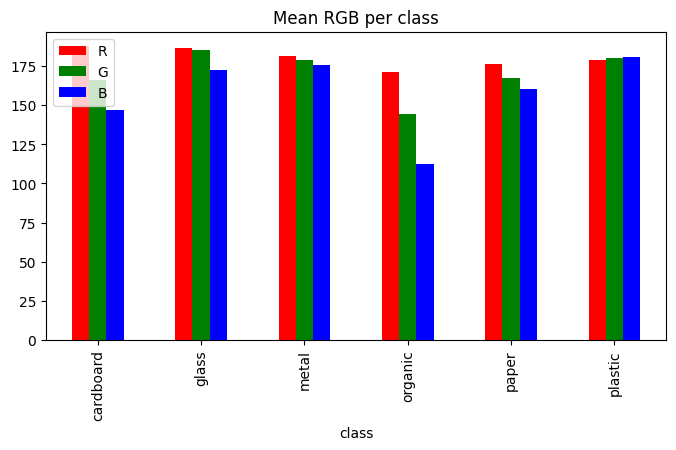

In [9]:
recs = []
for cls in CLASSES:
    for f in random.sample(list((DST/'train'/cls).glob('*')), 100):
        a = np.asarray(Image.open(f).convert('RGB').resize((64, 64)), dtype=np.float32)
        recs.append((cls, a.mean(), *a.mean(axis=(0, 1))))
df_col = pd.DataFrame(recs, columns=['class', 'brightness', 'R', 'G', 'B'])
print(df_col.groupby('class').mean().round(1))
df_col.boxplot(column='brightness', by='class', figsize=(8, 4)); plt.suptitle(''); plt.show()
df_col.groupby('class')[['R', 'G', 'B']].mean().plot(kind='bar', color=['r', 'g', 'b'], figsize=(8, 4))
plt.title('Mean RGB per class'); plt.show()

# 4. Preprocessing: resize to 224x224, normalize for MobileNetV2, and augmentation

In [1]:
import sys
sys.path.insert(0, '/content/waste-classifier')

ModuleNotFoundError: No module named 'tensorflow'

# 5. Model, evaluation, and saving